# Análisis exploratorio de datos (EDA) — instancia qap10

**Reto NTT DATA · Track A: asignación de vuelos de conexión a puertas de embarque.**

Este notebook explora la instancia MIPLIB `qap10` después de recuperar sus matrices:

- **F** (flujos): pasajeros que hacen transbordo entre los vuelos *i* y *k* (cada par se cuenta una sola vez).
- **D** (distancias): distancia a pie entre las puertas *j* y *l*.
- Objetivo: asignar una puerta distinta a cada vuelo minimizando $C = \sum_{i<k} F_{ik}\, D_{p(i)\,p(k)}$.
- Brecha (definición del reto, solo sobre soluciones válidas): $\text{gap}(\%) = 100\,\dfrac{C - 340}{340}$.

**Convenciones**

- En tablas y figuras los vuelos son **V1..V10** y las puertas **P1..P10** (en el código van de 0 a 9).
- Las unidades son **supuestos, no mediciones**: los porcentajes son relativos y reproducibles, no minutos ni metros reales.
- Paleta: Okabe-Ito (azul, bermellón, verde azulado), validada para daltonismo; mapas de calor en un solo tono azul.

**Cómo regenerarlo** (también rehace `docs/figures/*.png` y `docs/eda/*.csv`):

```bash
uv run jupyter nbconvert --to notebook --execute --inplace notebooks/01_data.ipynb
```

## 0. Configuración

In [1]:
import itertools
import time
from itertools import chain, islice
from math import factorial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.ticker import FuncFormatter
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr

from qap.data import load_instance
from qap.types import cost, costs

# Repo root = first parent folder holding pyproject.toml (works from notebooks/ or from the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
FIG, TAB = ROOT / "docs" / "figures", ROOT / "docs" / "eda"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
# Okabe-Ito (colorblind-safe). Slots used: blue, vermillion, bluish green (validated all-pairs, contrast >= 3:1).
BLUE, VERMILLION, GREEN = "#0072B2", "#D55E00", "#009E73"
# Sequential ramp: tint -> Okabe-Ito sky blue -> Okabe-Ito blue -> dark navy (one hue, light to dark).
SEQ = LinearSegmentedColormap.from_list("seq_okabe_blue", ["#dcecf7", "#56B4E9", "#0072B2", "#00395c"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
pd.set_option("display.precision", 3)
SRC = "Fuente: qap10 (MIPLIB), matrices F y D recuperadas del MPS. Unidades supuestas, no mediciones."


def save(fig, name):
    """Add the source note, save to docs/figures and show the figure inline."""
    if fig.get_layout_engine() is None:
        fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.text(0.01, 0.008, SRC, fontsize=7.5, color=INK2)
    fig.savefig(FIG / name, dpi=160)
    plt.show()


def pct(x, d=1):
    return f"{100 * x:.{d}f} %".replace(".", ",")


C_STAR = 340  # reference optimum of the full instance (challenge statement)


def gap_pct(c, ref=C_STAR):
    """Gap as defined by the challenge: 100 (C - 340) / 340. Only meaningful for valid assignments."""
    return 100 * (np.asarray(c, dtype=float) - ref) / ref

## 1. Carga y verificación de la instancia

`load_instance(10)` devuelve F y D recuperados del MPS por `qap.data` (verificación rank-1 bloque por bloque).
Aquí se comprueba además que D es exactamente la distancia Manhattan sobre una cuadrícula de 4 columnas.

In [2]:
inst = load_instance(10)
n, F, D, Fs = inst.n, inst.F, inst.D, inst.F_sym
iu = np.triu_indices(n, 1)
V, P = [f"V{i + 1}" for i in range(n)], [f"P{j + 1}" for j in range(n)]
coords = np.array([(j % 4, j // 4) for j in range(n)])  # gate j -> (column, row) on the 4-column grid
manhattan = np.abs(coords[:, None, 0] - coords[None, :, 0]) + np.abs(coords[:, None, 1] - coords[None, :, 1])
is_manhattan = bool(np.array_equal(D, manhattan))
assert is_manhattan
flows, dpairs = F[iu], D[iu]
total = int(flows.sum())
print(f"Instancia {inst.name}: óptimo de referencia = {inst.optimum}")
display(pd.DataFrame(Fs, index=V, columns=V).style.set_caption("F simétrica (pasajeros en conexión)"))
display(pd.DataFrame(D, index=P, columns=P).style.set_caption("D (distancia entre puertas)"))

Instancia qap10-n10: óptimo de referencia = 340


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10
V1,0,10,4,8,2,0,0,12,4,2
V2,10,0,6,0,4,4,4,0,8,10
V3,4,6,0,0,0,0,0,10,10,4
V4,8,0,0,0,10,4,4,20,0,0
V5,2,4,0,10,0,20,0,0,0,10
V6,0,4,0,4,20,0,10,2,2,10
V7,0,4,0,4,0,10,0,20,10,4
V8,12,0,10,20,0,2,20,0,0,0
V9,4,8,10,0,0,2,10,0,0,0
V10,2,10,4,0,10,10,4,0,0,0


,P1,P2,P3,P4,P5,P6,P7,P8,P9,P10
P1,0,1,2,3,1,2,3,4,2,3
P2,1,0,1,2,2,1,2,3,3,2
P3,2,1,0,1,3,2,1,2,4,3
P4,3,2,1,0,4,3,2,1,5,4
P5,1,2,3,4,0,1,2,3,1,2
P6,2,1,2,3,1,0,1,2,2,1
P7,3,2,1,2,2,1,0,1,3,2
P8,4,3,2,1,3,2,1,0,4,3
P9,2,3,4,5,1,2,3,4,0,1
P10,3,2,3,4,2,1,2,3,1,0


## 2. Perfil de los datos

In [3]:
f_counts = pd.Series(flows).value_counts().sort_index().rename("pares")
d_counts = pd.Series(dpairs).value_counts().sort_index().rename("pares")
overview = pd.Series({
    "vuelos": n, "puertas": n, "pares de vuelos": len(flows),
    "pares con flujo > 0": int((flows > 0).sum()), "densidad": round((flows > 0).mean(), 3),
    "flujo total": total, "flujo mínimo > 0": int(flows[flows > 0].min()), "flujo máximo": int(flows.max()),
    "mediana de flujo (pares > 0)": float(np.median(flows[flows > 0])),
    "mcd de los flujos": int(np.gcd.reduce(flows[flows > 0])),
    "distancias distintas (puertas)": sorted(set(dpairs.tolist())),
    "distancia media (pares de puertas)": round(dpairs.mean(), 3), "distancia máxima": int(D.max()),
    "D simétrica": bool(np.array_equal(D, D.T)), "D = Manhattan en cuadrícula de 4 columnas": is_manhattan,
}, name="valor")
overview.to_csv(TAB / "overview.csv", header=True)
f_counts.to_csv(TAB / "flow_value_counts.csv")
d_counts.to_csv(TAB / "distance_value_counts.csv")
display(overview.to_frame())
display(pd.DataFrame({"flujo": f_counts.index, "pares": f_counts.values}).set_index("flujo").T)
display(pd.DataFrame({"distancia": d_counts.index, "pares": d_counts.values}).set_index("distancia").T)

,valor
vuelos,10
puertas,10
pares de vuelos,45
pares con flujo > 0,29
densidad,0.644
flujo total,228
flujo mínimo > 0,2
flujo máximo,20
mediana de flujo (pares > 0),8.0
mcd de los flujos,2


flujo,0,2,4,6,8,10,12,20
pares,16,4,9,1,2,9,1,3


distancia,1,2,3,4,5
pares,13,15,11,5,1


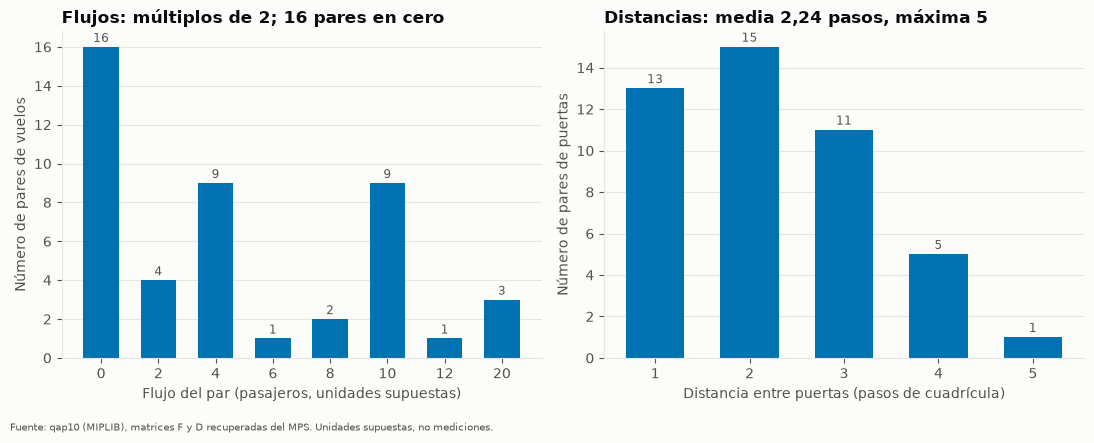

In [4]:
zero_pairs = int((flows == 0).sum())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
ax1.bar([str(int(v_)) for v_ in f_counts.index], f_counts.values, color=BLUE, width=0.62)
for x_, v_ in enumerate(f_counts.values):
    ax1.text(x_, v_ + 0.25, int(v_), ha="center", fontsize=8.5, color=INK2)
ax1.set_title(f"Flujos: múltiplos de 2; {zero_pairs} pares en cero")
ax1.set_xlabel("Flujo del par (pasajeros, unidades supuestas)")
ax1.set_ylabel("Número de pares de vuelos")
ax1.grid(axis="x", visible=False)
ax2.bar([str(int(v_)) for v_ in d_counts.index], d_counts.values, color=BLUE, width=0.62)
for x_, v_ in enumerate(d_counts.values):
    ax2.text(x_, v_ + 0.25, int(v_), ha="center", fontsize=8.5, color=INK2)
ax2.set_title(f"Distancias: media {dpairs.mean():.2f} pasos, máxima {int(D.max())}".replace(".", ","))
ax2.set_xlabel("Distancia entre puertas (pasos de cuadrícula)")
ax2.set_ylabel("Número de pares de puertas")
ax2.grid(axis="x", visible=False)
save(fig, "flow_distance_hist.png")

**Lectura.** Datos completos (sin nulos ni duplicados). Los flujos son pocos valores discretos: 18 de los 29 pares
con flujo valen 4 o 10 y tres pares excepcionales valen 20. Como el mcd es 2, el dato de fondo son los múltiplos
1, 2, 3, 4, 5, 6 y 10 (el factor viene de la escala del MPS). 16 de 45 pares de vuelos no comparten pasajeros.
El 62 % de los pares de puertas está a 1 o 2 pasos.

## 3. Patrones en los flujos entre vuelos

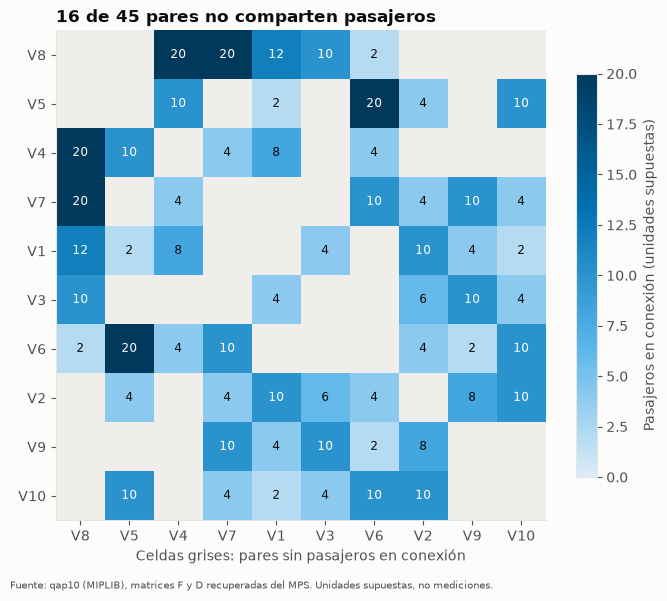

In [5]:
order = leaves_list(linkage(pdist(Fs), method="average"))  # similar flights next to each other
M = Fs[np.ix_(order, order)].astype(float)
fig, ax = plt.subplots(figsize=(6.8, 5.9))
ax.grid(False)
ax.set_facecolor("#efeeea")
im_ = ax.imshow(np.where(M > 0, M, np.nan), cmap=SEQ, vmin=0, vmax=Fs.max())
ax.set_xticks(range(n), [V[i] for i in order])
ax.set_yticks(range(n), [V[i] for i in order])
for i in range(n):
    for j in range(n):
        if M[i, j] > 0:
            ax.text(j, i, int(M[i, j]), ha="center", va="center", fontsize=8.5,
                    color="white" if M[i, j] >= 10 else INK)
fig.colorbar(im_, ax=ax, shrink=0.8, label="Pasajeros en conexión (unidades supuestas)")
ax.set_title(f"{zero_pairs} de {len(flows)} pares no comparten pasajeros")
ax.set_xlabel("Celdas grises: pares sin pasajeros en conexión")
save(fig, "flows_heatmap.png")

,vuelo,socios,pasajeros_en_conexion,participacion,mayor_flujo,socio_principal
1,V8,5,64,14.0%,20,V4
2,V6,7,52,11.4%,20,V5
3,V7,6,52,11.4%,20,V8
4,V2,7,46,10.1%,10,V1
5,V4,5,46,10.1%,20,V8
6,V5,5,46,10.1%,20,V6
7,V1,7,42,9.2%,12,V8
8,V10,6,40,8.8%,10,V2
9,V3,5,34,7.5%,10,V8
10,V9,5,34,7.5%,10,V3


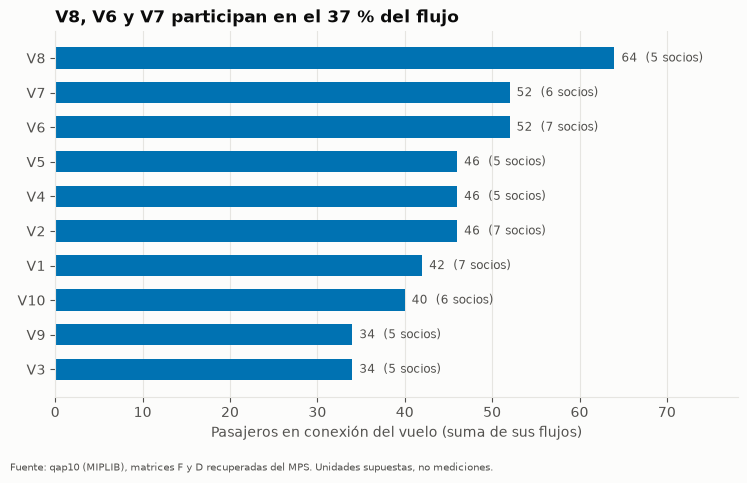

In [6]:
strength, degree = Fs.sum(1), (Fs > 0).sum(1)
flights = pd.DataFrame({
    "vuelo": V, "socios": degree, "pasajeros_en_conexion": strength.astype(int),
    "participacion": strength / (2 * total), "mayor_flujo": Fs.max(1).astype(int),
    "socio_principal": [V[j] for j in Fs.argmax(1)],
}).sort_values("pasajeros_en_conexion", ascending=False, kind="stable").reset_index(drop=True)
flights.index += 1
flights.to_csv(TAB / "flights.csv", index_label="rank")
display(flights.style.format({"participacion": "{:.1%}"}).set_caption(
    "Participación = pasajeros del vuelo / (2 × flujo total): suma 100 % porque cada transbordo involucra dos vuelos"))

fl = flights.sort_values("pasajeros_en_conexion", kind="stable")
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.barh(fl.vuelo, fl.pasajeros_en_conexion, color=BLUE, height=0.62)
for y, (s, d_) in enumerate(zip(fl.pasajeros_en_conexion, fl.socios)):
    ax.text(s + 0.8, y, f"{s}  ({d_} socios)", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(0, fl.pasajeros_en_conexion.max() * 1.22)
top3 = flights.head(3)
names3 = f"{', '.join(top3.vuelo[:-1])} y {top3.vuelo.iloc[-1]}"
ax.set_title(f"{names3} participan en el {pct(top3.participacion.sum(), 0)} del flujo")
ax.set_xlabel("Pasajeros en conexión del vuelo (suma de sus flujos)")
ax.grid(axis="y", visible=False)
save(fig, "flight_strength.png")

,par,flujo,participacion,acumulada
0,V4-V8,20,8.8%,8.8%
1,V5-V6,20,8.8%,17.5%
2,V7-V8,20,8.8%,26.3%
3,V1-V8,12,5.3%,31.6%
4,V1-V2,10,4.4%,36.0%
5,V2-V10,10,4.4%,40.4%
6,V3-V8,10,4.4%,44.7%
7,V3-V9,10,4.4%,49.1%
8,V4-V5,10,4.4%,53.5%
9,V5-V10,10,4.4%,57.9%


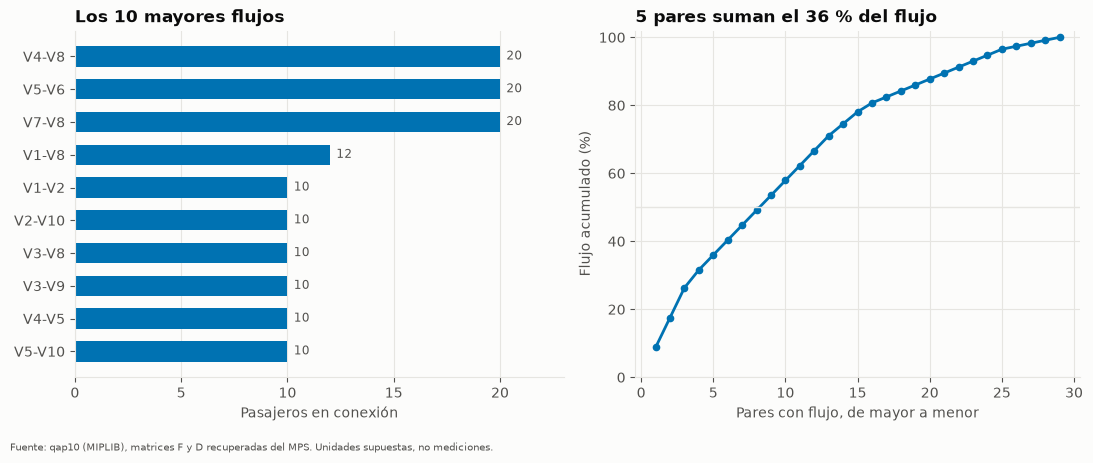

In [7]:
pairs = pd.DataFrame({"par": [f"{V[i]}-{V[k]}" for i, k in zip(*iu)], "flujo": flows})
pairs = pairs[pairs.flujo > 0].sort_values("flujo", ascending=False, kind="stable").reset_index(drop=True)
pairs["participacion"] = pairs.flujo / total
pairs["acumulada"] = pairs.participacion.cumsum()
pairs.to_csv(TAB / "pairs.csv", index=False)
display(pairs.head(10).style.format({"participacion": "{:.1%}", "acumulada": "{:.1%}"}))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
top10 = pairs.head(10).iloc[::-1]
ax1.barh(top10.par, top10.flujo, color=BLUE, height=0.62)
for y, v_ in enumerate(top10.flujo):
    ax1.text(v_ + 0.3, y, int(v_), va="center", fontsize=8.5, color=INK2)
ax1.set_xlim(0, pairs.flujo.max() * 1.15)
ax1.set_title("Los 10 mayores flujos")
ax1.set_xlabel("Pasajeros en conexión")
ax1.grid(axis="y", visible=False)
ax2.plot(range(1, len(pairs) + 1), pairs.acumulada * 100, color=BLUE, lw=2, marker="o", ms=4.5)
ax2.axhline(50, color=GRID, lw=1)
ax2.set_title(f"5 pares suman el {pct(pairs.acumulada.iloc[4], 0)} del flujo")
ax2.set_xlabel("Pares con flujo, de mayor a menor")
ax2.set_ylabel("Flujo acumulado (%)")
ax2.set_ylim(0, 102)
save(fig, "top_flows.png")

**Hallazgos.**

- **V8 es el vuelo hub:** 64 pasajeros; tres de sus cinco socios son flujos grandes (V4 y V7 con 20, V1 con 12).
- **Los flujos no están muy concentrados:** los tres pares de 20 (V4–V8, V5–V6, V7–V8) suman 26 %; los 5 mayores, 36 %;
  los 10 mayores, 58 %. Hay una cola larga de pares de 4 y 10 que también pesa en el costo.
- El grafo de flujos no es completo (densidad 0,64).

## 4. Las puertas

puerta,fila,columna,suma_distancias,distancia_media,rank_centralidad
P6,2,2,15,1.67,1
P2,1,2,17,1.89,2
P7,2,3,17,1.89,2
P3,1,3,19,2.11,4
P5,2,1,19,2.11,4
P1,1,1,21,2.33,6
P10,3,2,21,2.33,6
P8,2,4,23,2.56,8
P4,1,4,25,2.78,9
P9,3,1,25,2.78,9


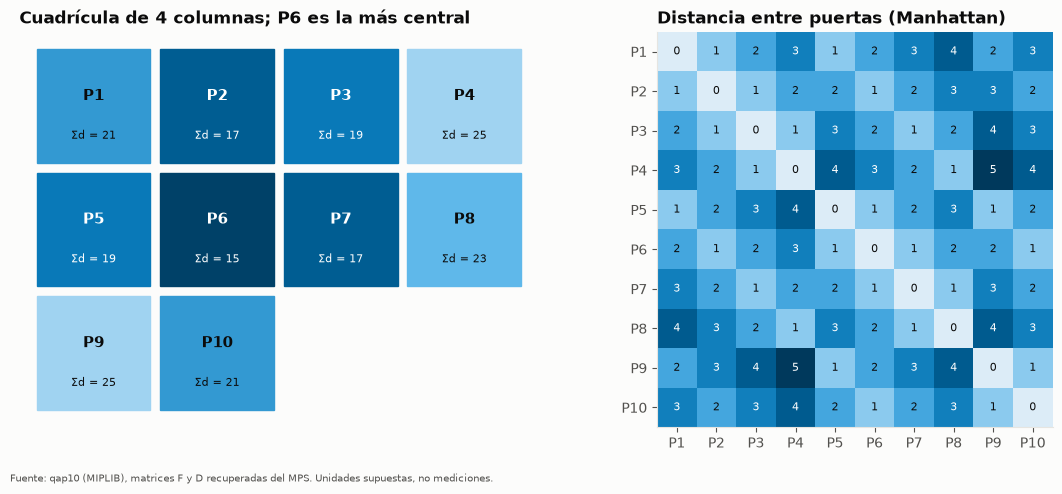

In [8]:
closeness = D.sum(1)
gates = pd.DataFrame({
    "puerta": P, "fila": coords[:, 1] + 1, "columna": coords[:, 0] + 1,
    "suma_distancias": closeness, "distancia_media": closeness / (n - 1),
}).sort_values("suma_distancias", kind="stable")
gates["rank_centralidad"] = gates["suma_distancias"].rank(method="min").astype(int)
gates.to_csv(TAB / "gates.csv", index=False)
display(gates.style.hide(axis="index").format({"distancia_media": "{:.2f}"}))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.9), gridspec_kw={"width_ratios": [1, 1.05]})
norm = Normalize(closeness.min(), closeness.max())
for j in range(n):
    x_, y_ = coords[j]
    level = 1 - norm(closeness[j])  # 1 = most central
    ax1.add_patch(plt.Rectangle((x_ - 0.46, y_ - 0.46), 0.92, 0.92, color=SEQ(0.15 + 0.8 * level)))
    tcol = "white" if level > 0.45 else INK
    ax1.text(x_, y_ - 0.08, P[j], ha="center", va="center", fontsize=11, fontweight="bold", color=tcol)
    ax1.text(x_, y_ + 0.24, f"Σd = {closeness[j]}", ha="center", va="center", fontsize=8, color=tcol)
ax1.set_xlim(-0.6, 3.6)
ax1.set_ylim(2.6, -0.6)
ax1.set_aspect("equal")
ax1.axis("off")
ax1.set_title(f"Cuadrícula de 4 columnas; {gates.puerta.iloc[0]} es la más central")
ax2.imshow(D, cmap=SEQ, vmin=0, vmax=D.max())
ax2.grid(False)
ax2.set_xticks(range(n), P)
ax2.set_yticks(range(n), P)
for i in range(n):
    for j in range(n):
        ax2.text(j, i, D[i, j], ha="center", va="center", fontsize=8, color="white" if D[i, j] >= 3 else INK)
ax2.set_title("Distancia entre puertas (Manhattan)")
save(fig, "gate_grid.png")

**Lectura.** P6 es la puerta más central (suma de distancias 15); P4 y P9 son las más periféricas (25) y están a
5 pasos entre sí. Como el costo premia la cercanía, la centralidad importa para los vuelos con más pasajeros.

## 5. Paisaje del costo: las 3 628 800 asignaciones, exacto

Se enumeran todas las permutaciones (por bloques, sin guardarlas todas en memoria). Las cifras no son una muestra.
También se cuentan las simetrías de D (permutaciones de puertas que dejan D igual).

In [9]:
t0 = time.perf_counter()
NEAR = 380
allc = np.empty(factorial(n), dtype=np.int16)
pos, near, aut = 0, [], 0
D8 = D.astype(np.int8)
gen = itertools.permutations(range(n))
while True:
    chunk = np.fromiter(chain.from_iterable(islice(gen, 200_000)), dtype=np.int8)
    if chunk.size == 0:
        break
    chunk = chunk.reshape(-1, n).astype(np.int64)
    c = costs(chunk, inst)
    allc[pos:pos + len(c)] = c
    pos += len(c)
    if (sel := c <= NEAR).any():
        near.append(chunk[sel])
    aut += int((D8[chunk[:, :, None], chunk[:, None, :]] == D8).all(axis=(1, 2)).sum())
near = np.concatenate(near)
print(f"Enumeración completa en {time.perf_counter() - t0:.1f} s")

opt = int(allc.min())
n_opt = int((allc == opt).sum())
opt_perms = near[costs(near, inst) == opt]
opt_perm = opt_perms[0]
assert opt == inst.optimum == 340
levels, counts = np.unique(allc, return_counts=True)
ident = cost(np.arange(n), inst)
mean_exact = float(allc.mean())
assert abs(mean_exact - total * D.sum() / (n * (n - 1))) < 1e-6  # closed form: E[cost] = sum(F) * mean off-diagonal D
landscape = pd.Series({
    "permutaciones": len(allc), "costo mínimo": opt, "permutaciones óptimas": n_opt,
    "segundo mejor costo": int(levels[1]), "permutaciones con el segundo mejor costo": int(counts[1]),
    "costo medio (exacto)": round(mean_exact, 2), "desviación estándar": round(float(allc.std()), 2),
    "mediana": float(np.median(allc)), "costo máximo": int(allc.max()),
    "costo de la asignación identidad": ident,
    "% de asignaciones mejores que la identidad": round(100 * (allc < ident).mean(), 2),
    "asignaciones con gap ≤ 1 %": int((gap_pct(allc) <= 1).sum()),
    "asignaciones con gap ≤ 5 %": int((gap_pct(allc) <= 5).sum()),
    "asignaciones con gap ≤ 10 %": int((gap_pct(allc) <= 10).sum()),
    "asignaciones con gap ≤ 20 %": int((gap_pct(allc) <= 20).sum()),
    "simetrías de D": aut,
    "ahorro del óptimo vs media aleatoria (1 − 340/media)": round(1 - opt / mean_exact, 4),
    "desviaciones estándar entre media y óptimo": round((mean_exact - opt) / float(allc.std()), 2),
}, name="valor")
landscape.to_csv(TAB / "landscape.csv", header=True)
pd.DataFrame({"costo": levels[:30], "asignaciones": counts[:30]}).to_csv(TAB / "lowest_cost_levels.csv", index=False)
display(landscape.to_frame())
print("Asignación óptima:", "  ".join(f"{V[i]}→{P[g]}" for i, g in enumerate(opt_perm)))

Enumeración completa en 4.8 s


,valor
permutaciones,3.629e+06
costo mínimo,3.400e+02
permutaciones óptimas,1.000e+00
segundo mejor costo,3.460e+02
permutaciones con el segundo mejor costo,1.000e+00
costo medio (exacto),5.117e+02
desviación estándar,3.918e+01
mediana,5.120e+02
costo máximo,6.660e+02
costo de la asignación identidad,4.540e+02


Asignación óptima: V1→P3  V2→P7  V3→P4  V4→P1  V5→P9  V6→P5  V7→P6  V8→P2  V9→P8  V10→P10


### Brecha (gap) de soluciones de referencia, con la fórmula del reto

$\text{gap}(\%) = 100\,(C - 340)/340$, calculada **solo sobre soluciones válidas**. Aquí todas lo son: cada permutación asigna
exactamente una puerta por vuelo. (Para los métodos cuánticos, las muestras inválidas se excluyen del gap y se reportan aparte
como fracción factible.)

In [10]:
reference = pd.DataFrame({
    "solución": ["óptimo", "segundo mejor", "identidad (Vi → Pi)", "media de una asignación al azar",
                 "mediana de una asignación al azar", "peor asignación"],
    "costo": [opt, int(levels[1]), ident, round(mean_exact, 1), float(np.median(allc)), int(allc.max())],
})
reference["gap (%)"] = gap_pct(reference["costo"]).round(2)
reference.to_csv(TAB / "gap_reference.csv", index=False)
display(reference.style.hide(axis="index").format({"gap (%)": "{:.2f}"}))

solución,costo,gap (%)
óptimo,340.000000,0.00
segundo mejor,346.000000,1.76
identidad (Vi → Pi),454.000000,33.53
media de una asignación al azar,511.700000,50.50
mediana de una asignación al azar,512.000000,50.59
peor asignación,666.000000,95.88


**Gap no es lo mismo que ahorro.** El gap mide cuánto peor que el óptimo es una solución (respecto de 340). El "ahorro"
de la narrativa mide cuánto menos camina el óptimo respecto de una referencia: **1 − 340/512 = 33,6 %** frente al azar.
Son cifras distintas: la asignación al azar tiene **gap 50,5 %**, y la identidad tiene **gap 33,5 %**, casi el mismo
número que el ahorro. En el pitch y en las diapositivas hay que nombrar siempre cuál de las dos se muestra.

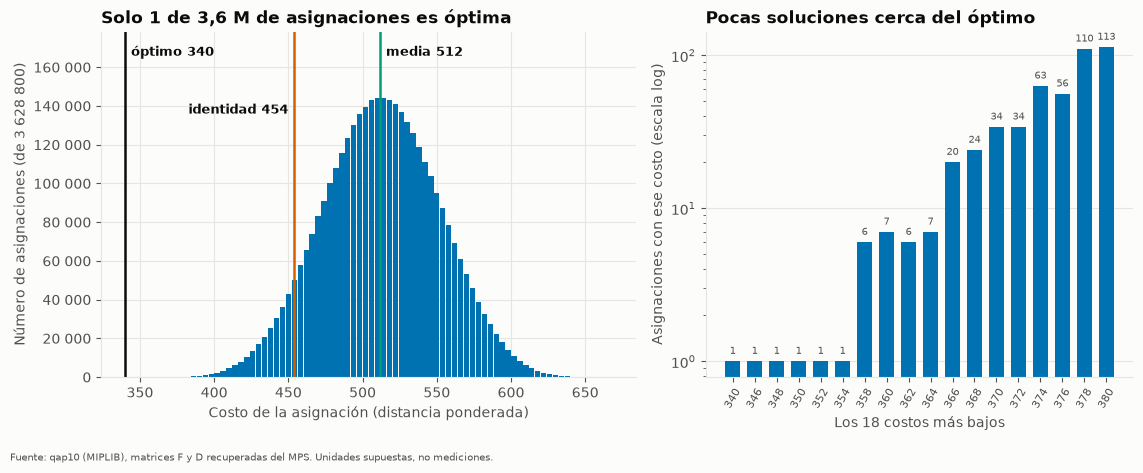

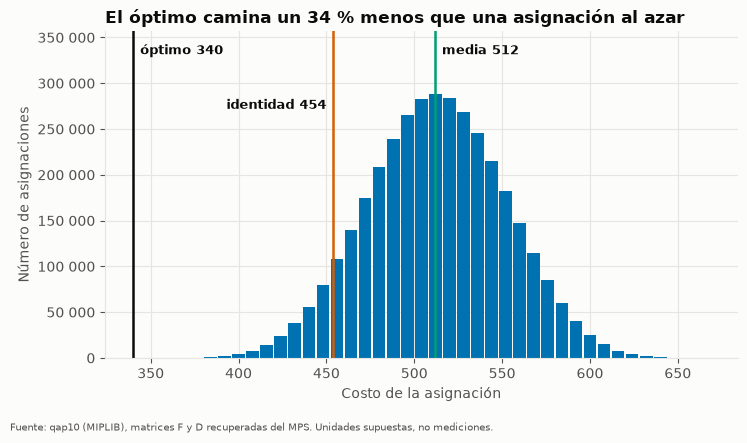

In [11]:
thousands = FuncFormatter(lambda v_, _: f"{int(v_):,}".replace(",", " "))


def mark_references(ax, values):
    """Vertical reference lines with labels placed above the bars (staggered to avoid collisions)."""
    ax.set_ylim(0, ax.get_ylim()[1] * 1.18)
    ytop = ax.get_ylim()[1] * 0.93
    for val, lab, col, ha, dx, hh in values:
        ax.axvline(val, color=col, lw=1.8)
        ax.text(val + dx, ytop * hh, lab, color=INK, fontsize=9, fontweight="bold", ha=ha)


refs = [(opt, f"óptimo {opt}", INK, "left", 4, 1.0), (ident, f"identidad {ident}", VERMILLION, "right", -4, 0.82),
        (mean_exact, f"media {mean_exact:.0f}", GREEN, "left", 4, 1.0)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.7), gridspec_kw={"width_ratios": [1.25, 1]})
ax1.hist(allc, bins=np.arange(allc.min(), allc.max() + 5, 4), color=BLUE, rwidth=0.9)
ax1.set_xlabel("Costo de la asignación (distancia ponderada)")
ax1.set_ylabel("Número de asignaciones (de 3 628 800)")
ax1.yaxis.set_major_formatter(thousands)
mark_references(ax1, refs)
ax1.set_title(f"Solo {n_opt} de 3,6 M de asignaciones es óptima")
ax2.bar(levels[:18].astype(str), counts[:18], color=BLUE, width=0.7)
ax2.set_yscale("log")
for x_, v_ in enumerate(counts[:18]):
    ax2.text(x_, v_ * 1.12, int(v_), ha="center", fontsize=7.5, color=INK2)
ax2.set_xlabel("Los 18 costos más bajos")
ax2.set_ylabel("Asignaciones con ese costo (escala log)")
ax2.tick_params(axis="x", labelrotation=60, labelsize=8)
ax2.set_title("Pocas soluciones cerca del óptimo")
ax2.grid(axis="x", visible=False)
save(fig, "cost_distribution_exact.png")

# Single-panel version for the slides (same exact distribution, coarser bins).
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.hist(allc, bins=np.arange(allc.min(), allc.max() + 9, 8), color=BLUE, rwidth=0.9)
ax.yaxis.set_major_formatter(thousands)
mark_references(ax, refs)
ax.set_xlabel("Costo de la asignación")
ax.set_ylabel("Número de asignaciones")
ax.set_title(f"El óptimo camina un {pct(1 - opt / mean_exact, 0)} menos que una asignación al azar")
save(fig, "random_cost_hist.png")

**Hallazgos.**

- **Es una aguja en un pajar:** el óptimo (340) es **una sola permutación**; el segundo mejor (346) también es único, y solo
  6 asignaciones están a menos del 5 % del óptimo. La distribución es casi una campana (media 512, desviación 39) y el
  óptimo está a 4,4 desviaciones de la media.
- **No hay soluciones gemelas:** D no tiene simetrías (solo la identidad), así que no existen óptimos equivalentes por reflexión.
- **La asignación identidad ya es buena (454):** solo el 6,8 % de las asignaciones son mejores. Por eso el "ahorro frente a la
  identidad" (25 %) es menor que el "ahorro frente al azar" (34 %). En la historia hay que decir **"frente a una asignación al azar"**.
- Los costos siempre son pares (F es par).

## 6. Cómo es la asignación óptima

,óptima,identidad,aleatoria (esperada)
1,59.6%,44.7%,28.9%
2,34.2%,25.4%,33.3%
3,3.5%,15.8%,24.4%
≥4,2.6%,14.0%,13.3%


Distancia media por pasajero: óptima 1.49, identidad 1.99, azar 2.24


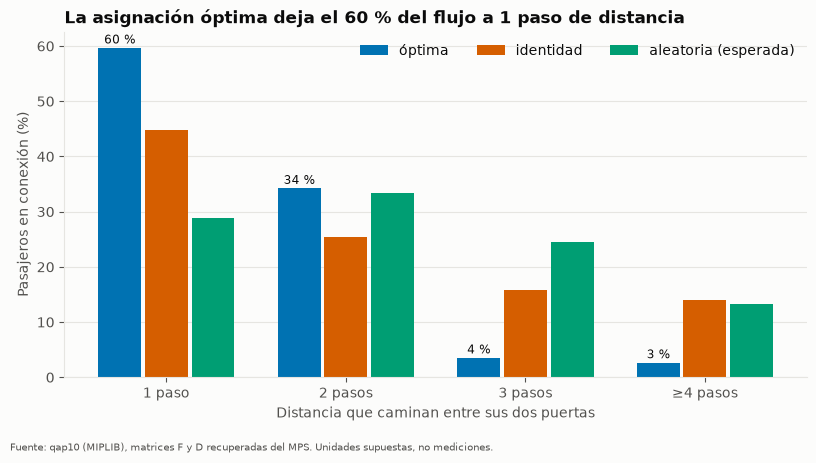

In [12]:
def share_by_distance(gate_dist):
    """Share of the total flow walked at each distance, for one assignment."""
    return {"1": flows[gate_dist == 1].sum() / total, "2": flows[gate_dist == 2].sum() / total,
            "3": flows[gate_dist == 3].sum() / total, "≥4": flows[gate_dist >= 4].sum() / total}


ordered = D[~np.eye(n, dtype=bool)]  # all ordered gate pairs (j != l): a random assignment draws from these uniformly
dist_share = pd.DataFrame({
    "óptima": share_by_distance(D[opt_perm[iu[0]], opt_perm[iu[1]]]),
    "identidad": share_by_distance(D[iu]),
    "aleatoria (esperada)": {"1": (ordered == 1).mean(), "2": (ordered == 2).mean(),
                             "3": (ordered == 3).mean(), "≥4": (ordered >= 4).mean()},
})
dist_share.to_csv(TAB / "flow_share_by_distance.csv")
display(dist_share.style.format("{:.1%}").set_caption("Porcentaje del flujo según la distancia que camina"))
print(f"Distancia media por pasajero: óptima {opt / total:.2f}, identidad {ident / total:.2f}, azar {mean_exact / total:.2f}")

fig, ax = plt.subplots(figsize=(8.2, 4.6))
cats = list(dist_share.index)
x = np.arange(len(cats))
w = 0.26
for k, (col, name) in enumerate([(BLUE, "óptima"), (VERMILLION, "identidad"), (GREEN, "aleatoria (esperada)")]):
    ax.bar(x + (k - 1) * w, dist_share[name] * 100, w * 0.92, color=col, label=name)
for xi, v_ in zip(x - w, dist_share["óptima"] * 100):
    ax.text(xi, v_ + 0.8, f"{v_:.0f} %", ha="center", fontsize=8.5, color=INK)
ax.set_xticks(x, [f"{c} paso" if c == "1" else f"{c} pasos" for c in cats])
ax.set_ylabel("Pasajeros en conexión (%)")
ax.set_xlabel("Distancia que caminan entre sus dos puertas")
ax.legend(frameon=False, ncols=3, loc="upper right")
ax.grid(axis="x", visible=False)
ax.set_title(f"La asignación óptima deja el {pct(dist_share.loc['1', 'óptima'], 0)} del flujo a 1 paso de distancia")
save(fig, "flow_by_distance.png")

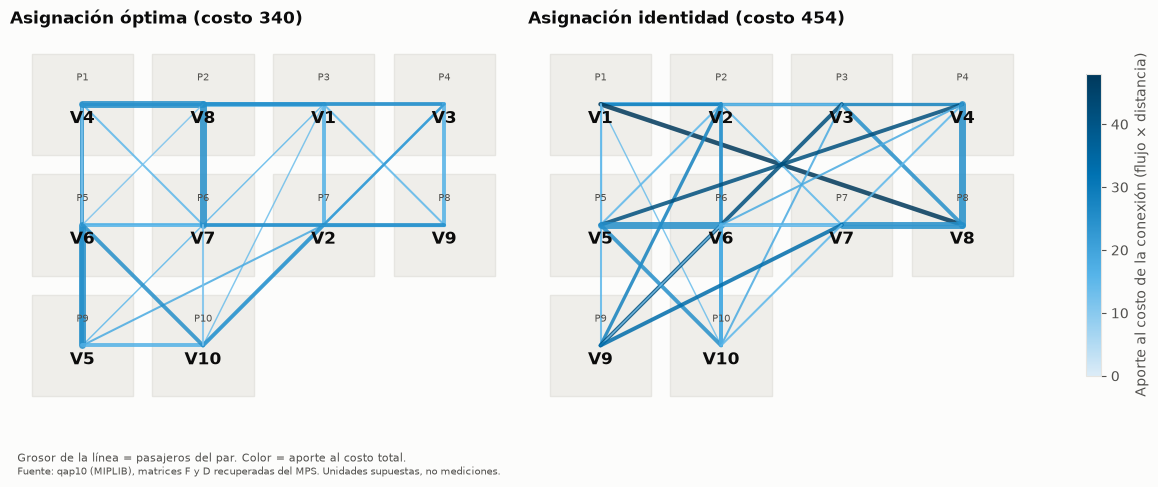

In [13]:
def contributions(perm):
    return flows * D[perm[iu[0]], perm[iu[1]]]


cnorm = Normalize(0, float(max(contributions(opt_perm).max(), contributions(np.arange(n)).max())))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), layout="constrained")
fig.get_layout_engine().set(rect=(0, 0.07, 1, 0.93))
for ax, perm, title in [(axes[0], opt_perm, f"Asignación óptima (costo {opt})"),
                        (axes[1], np.arange(n), f"Asignación identidad (costo {ident})")]:
    flight_at = {int(g): i for i, g in enumerate(perm)}
    for j in range(n):
        x_, y_ = coords[j]
        ax.add_patch(plt.Rectangle((x_ - 0.42, y_ - 0.42), 0.84, 0.84, facecolor="#efeeea", edgecolor=GRID, zorder=1))
        ax.text(x_, y_ - 0.22, P[j], ha="center", va="center", fontsize=7.5, color=INK2, zorder=4)
        ax.text(x_, y_ + 0.12, V[flight_at[j]], ha="center", va="center", fontsize=12, fontweight="bold", color=INK, zorder=4)
    for (i, k), f_, contrib in zip(zip(*iu), flows, contributions(perm)):
        if f_ > 0:
            g1, g2 = coords[perm[i]], coords[perm[k]]
            ax.plot([g1[0], g2[0]], [g1[1], g2[1]], color=SEQ(0.18 + 0.82 * cnorm(contrib)), lw=0.6 + f_ / 20 * 4.4,
                    alpha=0.85, zorder=2, solid_capstyle="round")
    ax.set_xlim(-0.6, 3.6)
    ax.set_ylim(2.6, -0.6)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)
fig.colorbar(plt.cm.ScalarMappable(norm=cnorm, cmap=SEQ), ax=axes, shrink=0.7,
             label="Aporte al costo de la conexión (flujo × distancia)")
fig.text(0.01, 0.035, "Grosor de la línea = pasajeros del par. Color = aporte al costo total.", fontsize=8, color=INK2)
save(fig, "optimal_assignment.png")

vuelo,puerta_optima,pasajeros_en_conexion,distancia_media_de_su_puerta
V1,P3,42,2.110000
V2,P7,46,1.890000
V3,P4,34,2.780000
V4,P1,46,2.330000
V5,P9,46,2.780000
V6,P5,52,2.110000
V7,P6,52,1.670000
V8,P2,64,1.890000
V9,P8,34,2.560000
V10,P10,40,2.330000


Spearman entre pasajeros del vuelo y distancia media de su puerta: rho = -0.70, p = 0.024 (n = 10)


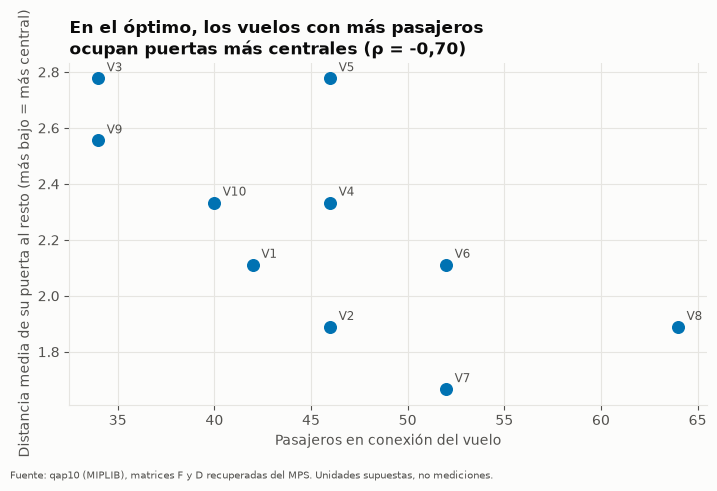

In [14]:
mean_dist_gate = closeness / (n - 1)
rho, pval = spearmanr(strength, mean_dist_gate[opt_perm])
assign = pd.DataFrame({"vuelo": V, "puerta_optima": [P[g] for g in opt_perm],
                       "pasajeros_en_conexion": strength.astype(int),
                       "distancia_media_de_su_puerta": mean_dist_gate[opt_perm].round(2)})
assign.to_csv(TAB / "optimal_assignment.csv", index=False)
display(assign.style.hide(axis="index"))
print(f"Spearman entre pasajeros del vuelo y distancia media de su puerta: rho = {rho:.2f}, p = {pval:.3f} (n = {n})")

fig, ax = plt.subplots(figsize=(7.2, 4.8))
ax.scatter(strength, mean_dist_gate[opt_perm], s=70, color=BLUE, zorder=3)
for i in range(n):
    ax.annotate(V[i], (strength[i], mean_dist_gate[opt_perm][i]), textcoords="offset points", xytext=(6, 5),
                fontsize=8.5, color=INK2)
ax.set_xlabel("Pasajeros en conexión del vuelo")
ax.set_ylabel("Distancia media de su puerta al resto (más bajo = más central)")
verdict = ("ocupan puertas más centrales" if rho < -0.3 else
           "sin relación clara con la centralidad" if abs(rho) <= 0.3 else "ocupan puertas menos centrales")
ax.set_title("\n".join(["En el óptimo, los vuelos con más pasajeros", f"{verdict} (ρ = {rho:.2f})".replace(".", ",")]))
save(fig, "hubs_vs_centrality.png")

**Hallazgos.**

- La asignación óptima deja **el 60 % del flujo a 1 paso** (identidad 45 %, azar 29 %) y solo un 6 % a 3 pasos o más.
  Distancia media por pasajero: 1,49 pasos (óptima) frente a 2,24 (azar).
- **Los vuelos con más pasajeros tienden a ocupar puertas más centrales** (ρ de Spearman −0,70, n = 10, p ≈ 0,02):
  evidencia moderada, no concluyente. V8 (64 pasajeros) está en P2, pegada a sus socios V4 (P1) y V1 (P3);
  V7 (52) ocupa P6, la más central.
- No es una regla simple: V5 (46) queda en P9, periférica, porque su socio principal V6 está en P5, a 1 paso.
  **Lo que se optimiza es la cercanía entre socios, no la centralidad por sí sola.**

## 7. ¿Qué tan difícil es para una búsqueda local?

2 000 descensos por intercambio de dos vuelos (siempre el mejor intercambio) desde asignaciones aleatorias, semilla 0.

,valor
arranques,2000.0
óptimos locales distintos,274.0
% que termina en el óptimo global (gap 0 %),3.2
% con gap ≤ 5 %,9.9
costo medio del óptimo local,372.9
gap medio (%),9.7
peor óptimo local,428.0
peor gap (%),25.9
pasos medios hasta converger,4.6


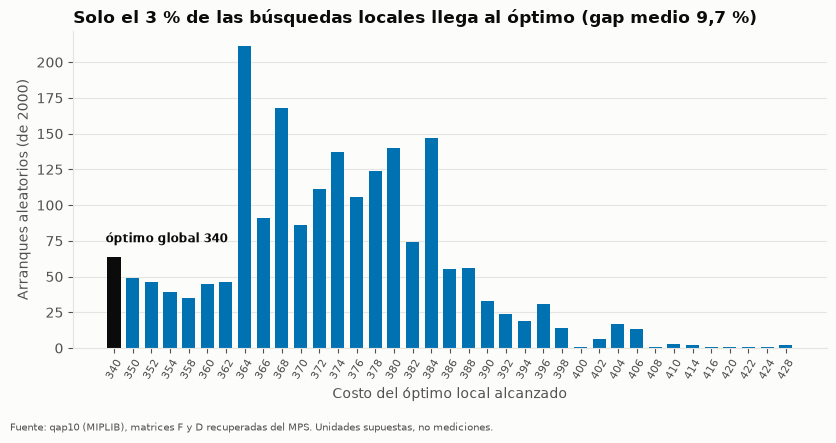

In [15]:
swap_pairs = np.array(list(itertools.combinations(range(n), 2)))
sa_, sb_, rows_ = swap_pairs[:, 0], swap_pairs[:, 1], np.arange(len(swap_pairs))


def descend(p):
    """Steepest descent over all pair swaps until no swap improves the cost."""
    c, steps = cost(p, inst), 0
    while True:
        nb = np.repeat(p[None, :], len(swap_pairs), 0)
        nb[rows_, sa_], nb[rows_, sb_] = p[sb_], p[sa_]
        cs = costs(nb, inst)
        m = cs.argmin()
        if cs[m] >= c:
            return p, c, steps
        p, c, steps = nb[m], int(cs[m]), steps + 1


rng = np.random.default_rng(0)
RUNS = 2000
runs = [descend(rng.permutation(n)) for _ in range(RUNS)]
lo_costs = np.array([c for _, c, _ in runs])
lo_steps = np.array([s for _, _, s in runs])
lo_gaps = gap_pct(lo_costs)
local = pd.Series({
    "arranques": RUNS, "óptimos locales distintos": len({tuple(p) for p, _, _ in runs}),
    "% que termina en el óptimo global (gap 0 %)": round(100 * (lo_costs == opt).mean(), 1),
    "% con gap ≤ 5 %": round(100 * (lo_gaps <= 5).mean(), 1),
    "costo medio del óptimo local": round(lo_costs.mean(), 1), "gap medio (%)": round(lo_gaps.mean(), 1),
    "peor óptimo local": int(lo_costs.max()), "peor gap (%)": round(lo_gaps.max(), 1),
    "pasos medios hasta converger": round(lo_steps.mean(), 1),
}, name="valor")
local.to_csv(TAB / "local_search.csv", header=True)
display(local.to_frame())

lo_counts = pd.Series(lo_costs).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.bar(lo_counts.index.astype(str), lo_counts.values,
       color=[INK if cst == opt else BLUE for cst in lo_counts.index], width=0.7)
x_opt = list(lo_counts.index).index(opt)
ax.text(x_opt - 0.45, lo_counts[opt] + 10, f"óptimo global {opt}", ha="left", fontsize=8.5, fontweight="bold")
ax.set_xlabel("Costo del óptimo local alcanzado")
ax.set_ylabel(f"Arranques aleatorios (de {RUNS})")
ax.tick_params(axis="x", labelrotation=60, labelsize=8)
ax.grid(axis="x", visible=False)
ax.set_title(f"Solo el {pct(local['% que termina en el óptimo global (gap 0 %)'] / 100, 0)} de las búsquedas locales "
             f"llega al óptimo (gap medio {local['gap medio (%)']:.1f} %)".replace(".", ","))
save(fig, "local_optima.png")

**Implicación.** El paisaje es rugoso: hay cientos de óptimos locales. Un descenso simple llega al óptimo global solo
3 de cada 100 veces; en promedio se queda con un gap de 9,7 % (el peor, 25,9 %) y converge en pocos pasos. Por eso la línea base clásica razonable
es **recocido simulado con reinicios**, y para un método híbrido conviene mover **varios vuelos a la vez** (k = 3 o 4),
no solo intercambios de pares.

## 8. Tamaño del problema y su efecto en una formulación cuántica

Subinstancias con los primeros N vuelos y N puertas (las que usa el reto: óptimos de control 24 para N=3 y 32 para N=4).
Con la codificación one-hot, una formulación QUBO usa N² qubits y solo N! de los 2^(N²) bitstrings son asignaciones válidas.

N,pares con flujo,flujo total,óptimo,media aleatoria,ahorro vs aleatoria,qubits (N²),permutaciones (N!),fracción factible (N!/2^N²),memoria statevector (bytes)
2,1,10,10,10.0,0.0%,4,2,1.25e-01,2.56e+02
3,3,20,24,26.7,10.0%,9,6,1.17e-02,8.19e+03
4,4,28,32,46.7,31.4%,16,24,3.66e-04,1.05e+06
5,7,44,58,88.0,34.1%,25,120,3.58e-06,5.37e+08
6,10,72,94,139.2,32.5%,36,720,1.05e-08,1.10e+12
7,13,90,112,171.4,34.7%,49,"5,040",8.95e-12,9.01e+15
8,18,154,214,308.0,30.5%,64,"40,320",2.19e-15,2.95e+20
9,23,188,264,417.8,36.8%,81,"362,880",1.50e-19,3.87e+25
10,29,228,340,511.7,33.6%,100,"3,628,800",2.86e-24,2.03e+31


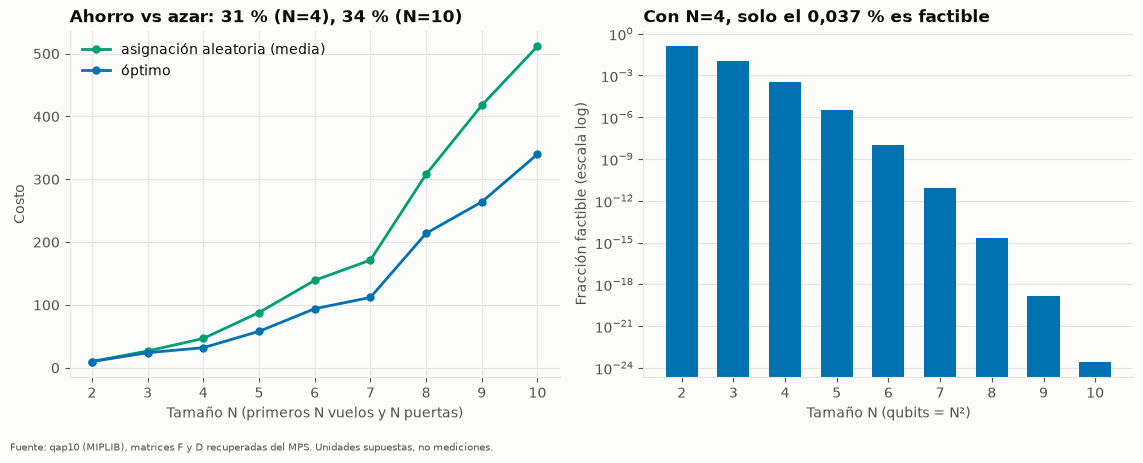

In [16]:
rows = []
for m in range(2, 11):
    im = load_instance(m)
    mean_m = im.F.sum() * im.D.sum() / (m * (m - 1))
    rows.append({
        "N": m, "pares con flujo": int((im.F > 0).sum()), "flujo total": int(im.F.sum()),
        "óptimo": im.optimum, "media aleatoria": round(mean_m, 1),
        "ahorro vs aleatoria": 1 - im.optimum / mean_m,
        "qubits (N²)": m * m, "permutaciones (N!)": factorial(m),
        "fracción factible (N!/2^N²)": factorial(m) / 2 ** (m * m),
        "memoria statevector (bytes)": 16 * 2 ** (m * m),
    })
scaling = pd.DataFrame(rows)
scaling.to_csv(TAB / "scaling.csv", index=False)
display(scaling.style.hide(axis="index").format({
    "ahorro vs aleatoria": "{:.1%}", "fracción factible (N!/2^N²)": "{:.2e}", "memoria statevector (bytes)": "{:.2e}",
    "media aleatoria": "{:.1f}", "permutaciones (N!)": "{:,}"}))

f4 = scaling.loc[scaling.N == 4, "fracción factible (N!/2^N²)"].iat[0]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.6))
ax1.plot(scaling.N, scaling["media aleatoria"], color=GREEN, lw=2, marker="o", ms=5, label="asignación aleatoria (media)")
ax1.plot(scaling.N, scaling["óptimo"], color=BLUE, lw=2, marker="o", ms=5, label="óptimo")
ax1.legend(frameon=False, loc="upper left")
ax1.set_xlabel("Tamaño N (primeros N vuelos y N puertas)")
ax1.set_ylabel("Costo")
s4 = scaling.loc[scaling.N == 4, "ahorro vs aleatoria"].iat[0]
s10 = scaling.loc[scaling.N == 10, "ahorro vs aleatoria"].iat[0]
ax1.set_title(f"Ahorro vs azar: {pct(s4, 0)} (N=4), {pct(s10, 0)} (N=10)")
ax2.bar(scaling.N.astype(str), scaling["fracción factible (N!/2^N²)"], color=BLUE, width=0.62)
ax2.set_yscale("log")
ax2.set_xlabel("Tamaño N (qubits = N²)")
ax2.set_ylabel("Fracción factible (escala log)")
ax2.set_title(f"Con N=4, solo el {pct(f4, 3)} es factible")
ax2.grid(axis="x", visible=False)
save(fig, "scaling_feasibility.png")

**Hallazgos.**

- **N=3 es demasiado fácil para una demo:** el óptimo ahorra solo 10 % frente al azar (6 permutaciones). **N=4 ya muestra un
  31 %**, parecido a la instancia completa (31–37 % desde N=4). Recomendación: N=4 como instancia principal de la demo cuántica.
- **Casi todos los bitstrings son inválidos:** con N=4 solo 24 de 65 536 (0,037 %). Elegir bitstrings al azar daría una
  asignación válida 1 de cada ~2 700 veces; cualquier método cuántico tiene que superar ese piso, y por eso la penalización λ
  y la fracción de muestras factibles son centrales en el estudio.
- Memoria de un statevector completo: N=4 → 1 MiB, N=5 → 512 MiB, N=6 → 1 TiB (coincide con la tabla del enunciado).
- **Gap en subinstancias:** el reto define el gap para la instancia completa (referencia 340). Para N=3 y N=4 usamos la misma
  fórmula con el óptimo de control de esa subinstancia (24 y 32); es una extensión nuestra y hay que decirlo al reportarla.
  Con tan pocas permutaciones (6 y 24), conviene reportar además si se alcanzó el óptimo exacto.

## 9. Escala de los coeficientes del QUBO

4050 términos, 2610 no nulos, 19 valores distintos no nulos, rango 2–100


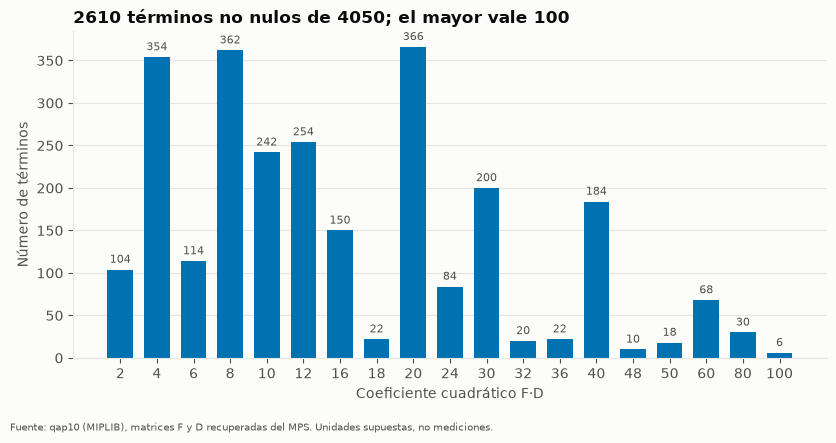

In [17]:
prod = np.multiply.outer(flows, ordered)  # F_ik * D_jl: the 4050 quadratic coefficients of the MPS objective
qubo_counts = pd.Series(prod.ravel()).value_counts().sort_index().rename("terminos")
qubo_counts.to_csv(TAB / "qubo_coefficients.csv")
nz = qubo_counts[qubo_counts.index > 0]
print(f"{prod.size} términos, {int(nz.sum())} no nulos, {len(nz)} valores distintos no nulos, rango {int(nz.index.min())}–{int(nz.index.max())}")

fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.bar([str(int(v_)) for v_ in nz.index], nz.values, color=BLUE, width=0.7)
for x_, v_ in enumerate(nz.values):
    ax.text(x_, v_ + 8, int(v_), ha="center", fontsize=8, color=INK2)
ax.set_xlabel("Coeficiente cuadrático F·D")
ax.set_ylabel("Número de términos")
ax.grid(axis="x", visible=False)
ax.set_title(f"{int(nz.sum())} términos no nulos de {prod.size}; el mayor vale {int(nz.index.max())}")
save(fig, "qubo_coefficients.png")

**Lectura.** Los coeficientes van de 2 a 100 (el 100 es F = 20 × D = 5). Una penalización λ debe ser comparable con estos
valores (del orden de decenas); su valor exacto se estudia en la parte de modelos.

## 10. La instancia en Qiskit

El método cuántico del proyecto se construye con **Qiskit**. Aquí se representa cada subinstancia como un `QuadraticProgram`
(`qiskit-optimization`), se convierte a QUBO con penalizaciones (`QuadraticProgramToQubo`) y a Hamiltoniano de Ising
(`to_ising`, con $x = (1 - Z)/2$). Se mide su tamaño y se **verifica que Qiskit reproduce exactamente el costo** de las
asignaciones válidas: así el modelo cuántico usa la misma instancia que exploramos en este notebook.

In [18]:
from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo


def to_quadratic_program(instance):
    """QAP sub-instance as a Qiskit QuadraticProgram: binary x_i_j (flight i at gate j), one-hot constraints."""
    m, Fm, Dm = instance.n, instance.F, instance.D
    qp = QuadraticProgram(instance.name)
    for i in range(m):
        for j in range(m):
            qp.binary_var(f"x_{i}_{j}")  # variable index i*m + j
    qp.minimize(quadratic={(f"x_{i}_{j}", f"x_{k}_{l}"): int(Fm[i, k] * Dm[j, l])
                           for i in range(m) for k in range(i + 1, m)
                           for j in range(m) for l in range(m) if j != l and Fm[i, k]})
    for i in range(m):
        qp.linear_constraint({f"x_{i}_{j}": 1 for j in range(m)}, "==", 1, f"flight_{i}")
    for j in range(m):
        qp.linear_constraint({f"x_{i}_{j}": 1 for i in range(m)}, "==", 1, f"gate_{j}")
    return qp


def one_hot(perms, m):
    """Rows of binary vectors x (index i*m + j) for a batch of permutations."""
    X = np.zeros((len(perms), m * m))
    X[np.arange(len(perms))[:, None], np.arange(m) * m + np.asarray(perms)] = 1
    return X


def ising_energy(op, offset, X):
    """Energy of computational basis states under a diagonal (Z-only) SparsePauliOp; qubit q <-> variable q."""
    z = 1 - 2 * X  # x = 1 -> Z eigenvalue -1
    zmask, coeffs = op.paulis.z, op.coeffs.real
    energy = np.full(len(X), float(offset))
    for t in range(len(op)):
        energy += coeffs[t] * z[:, zmask[t]].prod(axis=1)
    return energy


rng_q = np.random.default_rng(0)
qiskit_rows = []
for m in (3, 4, 5, 6, 10):
    im = load_instance(m)
    t_build = time.perf_counter()
    qp = to_quadratic_program(im)
    converter = QuadraticProgramToQubo()
    qubo = converter.convert(qp)
    op, offset = qubo.to_ising()
    t_build = time.perf_counter() - t_build
    if factorial(m) <= 720:  # every assignment for small N, a sample (plus the optimum) for N=10
        perms_q = np.array(list(itertools.permutations(range(m))))
    else:
        perms_q = np.vstack([opt_perm, np.arange(m), [rng_q.permutation(m) for _ in range(200)]])
    X = one_hot(perms_q, m)
    expected = costs(perms_q, im)
    from_qp = np.array([qp.objective.evaluate(x) for x in X])
    from_qubo = np.array([qubo.objective.evaluate(x) for x in X])
    from_ising = ising_energy(op, offset, X)
    qiskit_rows.append({
        "N": m, "variables binarias": qp.get_num_binary_vars(), "restricciones": qp.get_num_linear_constraints(),
        "qubits (Ising)": op.num_qubits, "términos de Pauli": len(op),
        "λ automático de Qiskit": converter.penalty, "mayor |coef| del objetivo": int(np.abs(qp.objective.quadratic.to_array()).max()),
        "asignaciones verificadas": len(perms_q),
        "costo = QuadraticProgram = QUBO = Ising": bool(np.allclose(from_qp, expected) and np.allclose(from_qubo, expected)
                                                        and np.allclose(from_ising, expected)),
        "construcción (s)": round(t_build, 2),
    })
qiskit_table = pd.DataFrame(qiskit_rows)
qiskit_table.to_csv(TAB / "qiskit_representation.csv", index=False)
display(qiskit_table.style.hide(axis="index"))
assert qiskit_table["costo = QuadraticProgram = QUBO = Ising"].all()

N,variables binarias,restricciones,qubits (Ising),términos de Pauli,λ automático de Qiskit,mayor |coef| del objetivo,asignaciones verificadas,costo = QuadraticProgram = QUBO = Ising,construcción (s)
3,9,6,9,45,161.000000,20,6,True,0.020000
4,16,8,16,112,561.000000,30,24,True,0.030000
5,25,10,25,265,1761.000000,40,120,True,0.060000
6,36,12,36,516,4177.000000,80,720,True,0.110000
10,100,20,100,3610,46057.000000,100,202,True,1.290000


**Lectura.**

- **Qiskit reproduce el costo exacto** en todas las asignaciones válidas probadas (todas para N ≤ 6; el óptimo, la identidad y
  200 al azar para N = 10), tanto en el `QuadraticProgram` como en el QUBO penalizado y en el Hamiltoniano de Ising: sobre una
  asignación válida la penalización vale 0, así que energía = costo. En asignaciones inválidas la energía incluye la penalización
  y **no** es un costo (por eso el gap se calcula solo sobre válidas).
- El número de términos de Pauli crece rápido (112 con N=4, más de 3 600 con N=10): además de los términos del objetivo, cada
  restricción one-hot aporta un término ZZ por cada par de variables de su fila o columna.
- **La penalización automática de Qiskit es muy grande:** 561 con N=4, cuyo mayor coeficiente es 30, y 46 057 con N=10, frente a
  un máximo de 100. Garantiza que el mínimo sea factible, pero aplana el paisaje de energía. Elegir un λ menor y justificado es parte del
  estudio de modelos (tarea M4).

## 11. Calidad de datos

In [19]:
checks = pd.Series({
    "sin valores faltantes": bool(np.isfinite(F).all() and np.isfinite(D).all()),
    "F y D son enteros ≥ 0": bool((F >= 0).all() and (D >= 0).all() and F.dtype.kind == D.dtype.kind == "i"),
    "F triangular superior (cada par una vez)": bool(np.array_equal(F, np.triu(F, 1))),
    "D simétrica con diagonal cero": bool(np.array_equal(D, D.T) and not np.diag(D).any()),
    "D = Manhattan en cuadrícula de 4 columnas": is_manhattan,
    "óptimos de control 24 / 32 / 340": [load_instance(m).optimum for m in (3, 4, 10)] == [24, 32, 340],
    "Qiskit (QuadraticProgram, QUBO, Ising) reproduce el costo": bool(qiskit_table["costo = QuadraticProgram = QUBO = Ising"].all()),
    "óptimo único": n_opt == 1,
}, name="resultado")
display(checks.to_frame())
assert checks.iloc[:-1].all()

,resultado
sin valores faltantes,True
F y D son enteros ≥ 0,True
F triangular superior (cada par una vez),True
D simétrica con diagonal cero,True
D = Manhattan en cuadrícula de 4 columnas,True
óptimos de control 24 / 32 / 340,True
"Qiskit (QuadraticProgram, QUBO, Ising) reproduce el costo",True
óptimo único,True


## 12. Datos listos para el equipo

Un solo archivo, `data/processed/qap10_summary.json`, con todo lo que necesitan los modelos (Diego) y la app (Felipe) sin
recalcular nada: F y D, el layout de puertas, los óptimos y las asignaciones óptimas de N = 2..10 y las referencias de gap y
ahorro. Convenciones: índices 0..9 en los arreglos (etiquetas V1..V10 y P1..P10 para mostrar), `perm[i]` = puerta del vuelo *i*.

In [20]:
import json

from qap.classical import solve_bruteforce

subinstances = []
for m in range(2, 11):
    im = load_instance(m)
    best = solve_bruteforce(im)
    assert best.cost == im.optimum
    mean_m = im.F.sum() * im.D.sum() / (m * (m - 1))
    subinstances.append({
        "n": m, "optimum": im.optimum, "optimal_perm": list(best.perm),
        "identity_cost": cost(np.arange(m), im), "random_mean_cost": round(float(mean_m), 4),
        "saving_vs_random": round(1 - im.optimum / mean_m, 4),
        "qubits_one_hot": m * m, "feasible_fraction_one_hot": factorial(m) / 2 ** (m * m),
    })

summary = {
    "source": "MIPLIB qap10 (https://miplib.zib.de/instance_details_qap10.html); F and D recovered from data/qap10.mps.gz",
    "units": "assumed, not measured",
    "cost": "C(perm) = sum over i<k of F[i][k] * D[perm[i]][perm[k]]  (each flight pair counted once)",
    "gap": "gap_pct = 100 * (C - 340) / 340, only for valid assignments (challenge definition, full instance)",
    "saving_vs_random": "1 - C / E[C_random]; a saving, not a gap",
    "flights": V, "gates": P,
    "gate_layout": {"columns": 4, "coords_col_row": coords.tolist()},
    "F_upper": F.tolist(), "D": D.tolist(),
    "subinstances": subinstances,
    "reference_solutions_n10": reference.rename(columns={"solución": "solution", "costo": "cost", "gap (%)": "gap_pct"})
                                        .to_dict(orient="records"),
    "flow_share_by_distance_n10": dist_share.round(4).to_dict(),
    "local_search_n10": {k: float(v) for k, v in local.items()},
    "qiskit_representation": qiskit_table.rename(columns={
        "variables binarias": "binary_vars", "restricciones": "constraints", "qubits (Ising)": "qubits",
        "términos de Pauli": "pauli_terms", "λ automático de Qiskit": "qiskit_default_penalty",
        "mayor |coef| del objetivo": "max_objective_coef", "asignaciones verificadas": "assignments_checked",
        "costo = QuadraticProgram = QUBO = Ising": "cost_matches", "construcción (s)": "build_seconds"}).to_dict(orient="records"),
}
out = ROOT / "data" / "processed" / "qap10_summary.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(summary, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o)),
               encoding="utf-8")
print(f"Escrito {out.relative_to(ROOT)} ({out.stat().st_size / 1024:.1f} KB)")
display(pd.DataFrame(subinstances).style.hide(axis="index").format(
    {"saving_vs_random": "{:.1%}", "feasible_fraction_one_hot": "{:.2e}", "random_mean_cost": "{:.1f}"}))

Escrito data\processed\qap10_summary.json (7.7 KB)


n,optimum,optimal_perm,identity_cost,random_mean_cost,saving_vs_random,qubits_one_hot,feasible_fraction_one_hot
2,10,"[0, 1]",10,10.0,0.0%,4,1.25e-01
3,24,"[0, 1, 2]",24,26.7,10.0%,9,1.17e-02
4,32,"[1, 2, 3, 0]",48,46.7,31.4%,16,3.66e-04
5,58,"[1, 0, 4, 2, 3]",98,88.0,34.1%,25,3.58e-06
6,94,"[1, 2, 3, 0, 4, 5]",134,139.2,32.5%,36,1.05e-08
7,112,"[6, 2, 3, 5, 1, 0, 4]",160,171.4,34.7%,49,8.95e-12
8,214,"[1, 0, 4, 2, 3, 7, 6, 5]",272,308.0,30.5%,64,2.19e-15
9,264,"[2, 6, 3, 0, 8, 4, 5, 1, 7]",378,417.8,36.8%,81,1.50e-19
10,340,"[2, 6, 3, 0, 8, 4, 5, 1, 7, 9]",454,511.7,33.6%,100,2.86e-24


## 13. Conclusiones

| Tema | Hallazgo | Implicación |
|---|---|---|
| Datos | Matrices completas, enteras, D = Manhattan en cuadrícula 4×3 (10 celdas), F verificado rank-1 | Las matrices son confiables; el costo se calcula una sola vez con `qap.types.cost` |
| Flujos | V8 es el hub (64); los 3 pares de 20 suman 26 % y hay una cola larga | No basta con juntar los pares grandes |
| Puertas | P6 es la más central; P4 y P9 las más periféricas | Los hubs tienden a puertas centrales (ρ = −0,70) |
| Paisaje | Óptimo 340 único entre 3,6 M; solo 6 asignaciones con gap ≤ 5 % | Aguja en un pajar; verificación contra una sola permutación |
| Gap vs ahorro | Gap del reto = 100 (C − 340)/340, solo válidas. Azar: gap 50,5 %; identidad: gap 33,5 % | El 34 % de la narrativa es un **ahorro** (1 − 340/512), no un gap: nombrarlo siempre |
| Narrativa | 34 % menos caminata que el azar; 60 % del flujo a 1 paso | Decir "frente al azar" (la identidad ya es buena) |
| Búsqueda | Descenso simple: 3 % llega al óptimo, gap medio 9,7 %; 274 óptimos locales | Recocido simulado con reinicios como línea base |
| Cuántico | N=4: 31 % de ahorro y 0,037 % de bitstrings factibles | N=4 como demo principal; λ y fracción factible son el eje |
| Qiskit | `QuadraticProgram`, QUBO e Ising reproducen el costo exacto; N=4 → 16 qubits y 112 términos de Pauli; λ automático 561 (mayor coeficiente 30) | El modelo cuántico parte de la misma instancia; hay que elegir un λ menor y justificarlo |

**Limitaciones.** Es una sola instancia y pequeña; la correlación hub–centralidad usa 10 puntos; la búsqueda local depende del
vecindario (intercambio de pares) y de la semilla; las unidades son supuestos.